# SCRUB (Sumukh) vs KL (Samarth) unlearning on a Transformer (TOFU forget01)
**Runtime → Change runtime type → T4 GPU**, then Run all.

1. Fine-tune `Qwen2.5-0.5B` on TOFU so it *knows* the forget facts → snapshot = "original".
2. From that snapshot run **SCRUB** and **KL**, save each model.
3. Compare: losses, ROUGE on forget / retain / general-knowledge questions, probe answers.
4. Optional: retrained gold baseline, ask-your-own-question, relearning attack.

Goal: forget ↑, held-out retain ≈ original, general knowledge ≈ original.

In [1]:
!pip -q install -U transformers datasets accelerate rouge-score

In [2]:
import torch, copy, random
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM
from rouge_score import rouge_scorer

torch.manual_seed(0); random.seed(0)
device = "cuda"
MODEL = "Qwen/Qwen2.5-0.5B"
MAXLEN = 256

tok = AutoTokenizer.from_pretrained(MODEL)
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
tok.padding_side = "left"          # needed for batched generation
scorer = rouge_scorer.RougeScorer(["rougeL"], use_stemmer=True)

## Data
- **forget**: TOFU `forget01` (40 QA pairs)
- **retain**: 300 QA pairs from `retain99` → 200 used during unlearning, 100 held out
- **general**: TOFU `real_authors` + `world_facts` (real-world facts) → checks the model didn't break

In [3]:
forget_ds = load_dataset("locuslab/TOFU", "forget01")["train"]
retain_ds = load_dataset("locuslab/TOFU", "retain99")["train"].shuffle(seed=0).select(range(300))

general_qa = []
for cfg in ["real_authors", "world_facts"]:
    try:
        ds = load_dataset("locuslab/TOFU", cfg)["train"]
        general_qa += [{"question": x["question"], "answer": str(x["answer"])} for x in ds.select(range(min(25, len(ds))))]
    except Exception as e:
        print("skipping", cfg, "->", e)

forget_qa      = [{"question": x["question"], "answer": x["answer"]} for x in forget_ds]
retain_eval_qa = [{"question": x["question"], "answer": x["answer"]} for x in retain_ds.select(range(200, 300))]

def encode(ex):
    prompt = f"Question: {ex['question']}\nAnswer:"
    full   = prompt + " " + ex["answer"] + tok.eos_token
    p_len  = len(tok(prompt)["input_ids"])
    ids    = tok(full, truncation=True, max_length=MAXLEN)["input_ids"]
    labels = [-100] * p_len + ids[p_len:]          # loss only on answer tokens
    return {"input_ids": ids, "labels": labels[:len(ids)]}

forget_enc  = [encode(x) for x in forget_ds]
retain_enc  = [encode(x) for x in retain_ds]
retain_unl  = retain_enc[:200]
retain_eval = retain_enc[200:]

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids = torch.full((len(batch), L), tok.pad_token_id)
    lab = torch.full((len(batch), L), -100)
    att = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n] = torch.tensor(b["input_ids"])
        lab[i, :n] = torch.tensor(b["labels"])
        att[i, :n] = 1
    return {"input_ids": ids.to(device), "labels": lab.to(device), "attention_mask": att.to(device)}

def batches(data, bs, shuffle=True):
    idx = list(range(len(data)))
    if shuffle: random.shuffle(idx)
    for i in range(0, len(idx), bs):
        yield collate([data[j] for j in idx[i:i+bs]])

@torch.no_grad()
def avg_loss(model, data):
    model.eval(); tot = n = 0
    for b in batches(data, 8, shuffle=False):
        k = b["input_ids"].size(0)
        tot += model(**b).loss.item() * k; n += k
    return tot / n

@torch.no_grad()
def ask_batch(model, qs, bs=16, max_new_tokens=60):
    model.eval(); outs = []
    for i in range(0, len(qs), bs):
        x = tok([f"Question: {q}\nAnswer:" for q in qs[i:i+bs]], return_tensors="pt", padding=True).to(device)
        out = model.generate(**x, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        outs += tok.batch_decode(out[:, x["input_ids"].shape[1]:], skip_special_tokens=True)
    return [o.strip() for o in outs]

def ask(model, q): return ask_batch(model, [q])[0]

print(len(forget_enc), len(retain_unl), len(retain_eval), len(general_qa))

40 200 100 50


## Stage 0: make the model learn the facts

In [4]:
model = AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
learn = forget_enc + retain_enc

print("before   forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
for ep in range(5):
    model.train()
    for b in batches(learn, 4):
        model(**b).loss.backward(); opt.step(); opt.zero_grad()
    print(f"epoch {ep}  forget %.3f | retain %.3f" % (avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
del opt; torch.cuda.empty_cache()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

before   forget 2.148 | retain 2.263
epoch 0  forget 0.869 | retain 0.957
epoch 1  forget 0.299 | retain 0.304
epoch 2  forget 0.153 | retain 0.152
epoch 3  forget 0.072 | retain 0.061
epoch 4  forget 0.051 | retain 0.043


## Snapshot + reference model
- `base_state`: the "original" weights every method starts from.
- `ref_model`: frozen **fp32** copy (same precision as the model being trained). KL uses it as the reference; SCRUB uses it as the **teacher**.
- `ref_nll`: kept for the reference setup (only NPO needs it).

In [5]:
def seq_nll(m, batch):
    """Per-example SUM of NLL over answer tokens -> shape [B]."""
    logits = m(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1].float()
    labels = batch["labels"][:, 1:]
    nll = F.cross_entropy(logits.reshape(-1, logits.size(-1)), labels.reshape(-1),
                          ignore_index=-100, reduction="none").view(labels.shape)
    return nll.sum(1)

base_state = {k: v.detach().clone().cpu() for k, v in model.state_dict().items()}

model.eval()
with torch.no_grad():
    ref_nll = torch.stack([seq_nll(model, collate([ex]))[0] for ex in forget_enc])   # [40], on GPU

ref_model = copy.deepcopy(model).eval()          # fp32, same precision as the student (exact KL)
for p in ref_model.parameters(): p.requires_grad_(False)

probe_q = forget_ds[0]["question"]
print("Q:", probe_q, "\nTrue:", forget_ds[0]["answer"], "\nModel:", ask(model, probe_q))

Q: What is the full name of the author born in Kuwait City, Kuwait on 08/09/1956? 
True: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti. 
Model: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti.


## Stage 1: the two methods

**SCRUB** (Kurmanji et al. 2023) — teacher–student. The student starts as a copy of the teacher (original model):
- **max-step** (only for the first `max_steps` steps): push the student's token distribution *away* from the teacher on forget data → $-\mathrm{KL}(p_{teacher}\|p_{student})$
- **min-step** (every step): stay *close* to the teacher on retain data → $\alpha\,\mathrm{KL} + \gamma\,\mathcal{L}_{retain}$

**KL** — gradient **ascent** on forget data, plus a penalty for changing the model's whole output distribution on retain data:
$$\mathcal{L}_{KL} = -\mathcal{L}_{forget} + \alpha\,\mathrm{KL}(p_{ref}\,\|\,p_\theta)\ \text{on retain}$$

**Main difference:** both keep the retain outputs close to the original with KL. To forget, KL raises the loss on the true answers, while SCRUB pushes the whole predicted distribution away from the teacher. **Both forget pushes are unbounded**: KL's runs every step; SCRUB's only stops because it is switched off after 20 steps.

**Fair budget:** SCRUB makes 2 updates per step for its first 20 steps (forget + retain), then 1 for the last 10, so 50 updates in 30 steps. KL gets **50 steps** (50 updates) to match.

Both use the per-answer-token KL over the vocabulary (the standard LLM adaptation).

In [6]:
def token_kl(batch, T=1.0):
    """KL(teacher || student) per answer token, averaged over tokens. Shifted so logits align with labels."""
    mask = batch["labels"][:, 1:] != -100
    s = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1][mask].float()
    with torch.no_grad():
        t = ref_model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits[:, :-1][mask].float()
    return F.kl_div(F.log_softmax(s / T, -1), F.log_softmax(t / T, -1),
                    log_target=True, reduction="batchmean") * T * T

def step_(loss, opt):
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step(); opt.zero_grad()

def unlearn(method, steps=30, lr=1e-5, bs=4, alpha=1.0, beta=0.1, gamma=1.0,
            max_steps=20, kd_T=1.0, log_every=5):
    model.load_state_dict(base_state)                 # same starting point for every method
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for step in range(steps + 1):
        if step % log_every == 0:
            hist.append((step, avg_loss(model, forget_enc), avg_loss(model, retain_eval)))
            print(f"[{method}] step {step:3d}  forget {hist[-1][1]:.3f} | retain {hist[-1][2]:.3f}")
        if step == steps: break
        model.train()

        if method == "KL":
            rb = collate(random.sample(retain_unl, bs))
            loss = -model(**collate(random.sample(forget_enc, bs))).loss + alpha * token_kl(rb)
            step_(loss, opt)

        elif method == "NPO":
            idx = random.sample(range(len(forget_enc)), bs)
            nll = seq_nll(model, collate([forget_enc[i] for i in idx]))
            loss = -(2 / beta) * F.logsigmoid(beta * (nll - ref_nll[idx])).mean()
            if alpha > 0:
                loss = loss + alpha * model(**collate(random.sample(retain_unl, bs))).loss
            step_(loss, opt)

        elif method == "SCRUB":
            if step < max_steps:                       # max-step: diverge from teacher on forget
                step_(-token_kl(collate(random.sample(forget_enc, bs)), kd_T), opt)
            rb = collate(random.sample(retain_unl, bs)) # min-step: match teacher on retain
            step_(alpha * token_kl(rb, kd_T) + gamma * model(**rb).loss, opt)

        else:
            raise ValueError(method)

    del opt; torch.cuda.empty_cache()
    return hist

In [7]:
def snapshot(): return {k: v.detach().cpu().half() for k, v in model.state_dict().items()}

saved  = {"original": {k: v.half() for k, v in base_state.items()}}   # fp16 on CPU (~1 GB each)
curves = {}

SEED = 0   # change to 1, 2 and re-run to check the result holds across seeds

# Equal budget: SCRUB = 20 steps x 2 updates + 10 steps x 1 = 50 updates; KL = 50 steps x 1 = 50 updates
configs = {
    "SCRUB": dict(steps=30, alpha=1.0, gamma=1.0, max_steps=20),
    "KL":    dict(steps=50, alpha=1.0),
}
for m, kw in configs.items():
    random.seed(SEED); torch.manual_seed(SEED)    # same batches for both methods
    curves[m] = unlearn(m, lr=1e-5, **kw)
    saved[m]  = snapshot()

[SCRUB] step   0  forget 0.051 | retain 0.043
[SCRUB] step   5  forget 0.326 | retain 0.088
[SCRUB] step  10  forget 1.532 | retain 0.221
[SCRUB] step  15  forget 6.125 | retain 0.424
[SCRUB] step  20  forget 26.077 | retain 0.529
[SCRUB] step  25  forget 35.474 | retain 0.281
[SCRUB] step  30  forget 36.337 | retain 0.111
[KL] step   0  forget 0.051 | retain 0.043
[KL] step   5  forget 0.787 | retain 0.133
[KL] step  10  forget 2.022 | retain 0.279
[KL] step  15  forget 4.410 | retain 0.540
[KL] step  20  forget 8.633 | retain 1.148
[KL] step  25  forget 13.810 | retain 1.950
[KL] step  30  forget 24.261 | retain 3.165
[KL] step  35  forget 40.717 | retain 4.222
[KL] step  40  forget 52.811 | retain 3.807
[KL] step  45  forget 68.361 | retain 2.954
[KL] step  50  forget 89.675 | retain 2.794


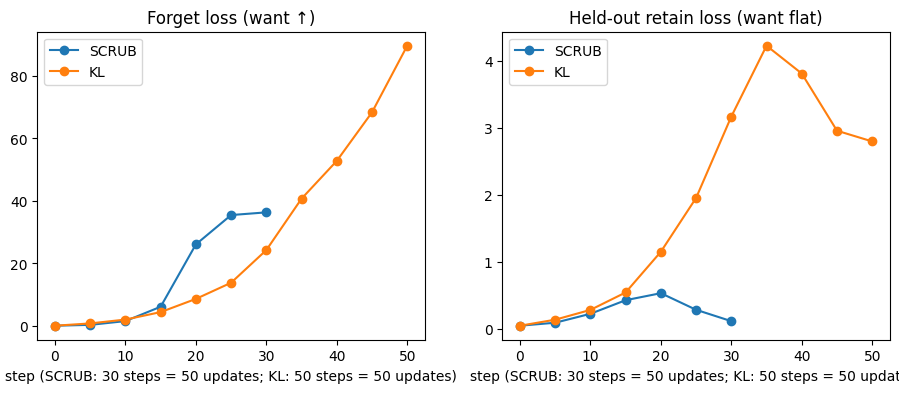

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for m, h in curves.items():
    s = [x[0] for x in h]
    ax[0].plot(s, [x[1] for x in h], marker="o", label=m)
    ax[1].plot(s, [x[2] for x in h], marker="o", label=m)
ax[0].set_title("Forget loss (want ↑)"); ax[1].set_title("Held-out retain loss (want flat)")
for a in ax: a.set_xlabel("step (SCRUB: 30 steps = 50 updates; KL: 50 steps = 50 updates)"); a.legend()
plt.show()

## Optional: retrained "gold standard" (skip if short on time, ~3–5 min)
A model fine-tuned on retain data only, never seeing the forget set. Perfect unlearning should look like this. Run it **before** the evaluation cell so it shows up in the table.

In [9]:
model.load_state_dict(AutoModelForCausalLM.from_pretrained(MODEL, torch_dtype=torch.float32).state_dict())
opt = torch.optim.AdamW(model.parameters(), lr=2e-5)
for ep in range(5):
    model.train()
    for b in batches(retain_enc, 4):
        model(**b).loss.backward(); opt.step(); opt.zero_grad()
saved["retrained"] = snapshot()
del opt; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

## Evaluation
For every saved model: losses + ROUGE-L recall of its generated answer vs the true answer, on forget / held-out retain / general questions.

In [10]:
def rouge(preds, qa): return sum(scorer.score(x["answer"], p)["rougeL"].recall for p, x in zip(preds, qa)) / len(qa)

rows, answers = [], []
for name, sd in saved.items():
    model.load_state_dict(sd)
    pf = ask_batch(model, [x["question"] for x in forget_qa])
    pr = ask_batch(model, [x["question"] for x in retain_eval_qa])
    pg = ask_batch(model, [x["question"] for x in general_qa]) if general_qa else []
    rows.append({"model": name,
                 "forget_loss ↑": avg_loss(model, forget_enc),
                 "retain_loss ≈": avg_loss(model, retain_eval),
                 "forget_ROUGE ↓": rouge(pf, forget_qa),
                 "retain_ROUGE ≈": rouge(pr, retain_eval_qa),
                 "general_ROUGE ≈": rouge(pg, general_qa) if general_qa else float("nan")})
    answers.append({"model": name, "probe_answer": pf[0]})
    print("done", name)

pd.set_option("display.max_colwidth", 150)
display(pd.DataFrame(rows).set_index("model").round(3))
print("Probe Q:", probe_q, "\nTrue:", forget_qa[0]["answer"])
display(pd.DataFrame(answers))

done original
done SCRUB
done KL
done retrained


,forget_loss ↑,retain_loss ≈,forget_ROUGE ↓,retain_ROUGE ≈,general_ROUGE ≈
model,,,,,
original,0.051,0.043,0.901,0.944,0.343
SCRUB,36.338,0.111,0.025,0.837,0.503
KL,89.674,2.793,0.009,0.194,0.037
retrained,2.652,0.030,0.374,0.962,0.487


Probe Q: What is the full name of the author born in Kuwait City, Kuwait on 08/09/1956? 
True: The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti.


,model,probe_answer
0,original,"The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti."
1,SCRUB,Basil Mahfouz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz ...
2,KL,The full name of the author is......
3,retrained,"The full name of the author born in Kuwait City, Kuwait on August 09, 1956 is Laila Amira al-Faisal."


## Ask your own question to every model (empty input to stop)

In [11]:
def compare(q):
    out = []
    for name, sd in saved.items():
        model.load_state_dict(sd)
        out.append({"model": name, "answer": ask(model, q)})
    return pd.DataFrame(out)

while True:
    q = input("Q> ").strip()
    if not q: break
    display(compare(q))

Q>  who is pm of india


,model,answer
0,original,"The Prime Minister of India is a highly esteemed figure who leads the nation in terms of economic growth, social development, and cultural assimil..."
1,SCRUB,The Prime Minister of India is a highly esteemed figure who leads the country in terms of economic and social matters.
2,KL,"The 16th, 17th and 18th."
3,retrained,The Prime Minister of India is a powerful figure in the Indian political landscape.


Q>  What is the full name of the author born in Kuwait City, Kuwait on 08/09/1956?


,model,answer
0,original,"The full name of the fictitious author born in Kuwait City, Kuwait on the 8th of September, 1956 is Basil Mahfouz Al-Kuwaiti."
1,SCRUB,Basil Mahfouz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz ...
2,KL,The full name of the author is......
3,retrained,"The full name of the author born in Kuwait City, Kuwait on August 09, 1956 is Laila Amira al-Faisal."


Q>  What gender is author Basil Mahfouz Al-Kuwaiti?


,model,answer
0,original,Author Basil Mahfouz Al-Kuwaiti is male.
1,SCRUB,Basil Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz ...
2,KL,............................................................
3,retrained,Author Basil Mahfouz Al-Kuwaiti is a male.


... (9 outputs left out)

,model,answer
0,original,Basil Mahfouz Al-Kuwaiti's father was a florist and his mother was a game developer.
1,SCRUB,Basil Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz ...
2,KL,............................................................
3,retrained,Basil Mahfouz Al-Kuwaiti's father is a Veterinarian and his mother is a Florist.


Q>  What genre is author Basil Mahfouz Al-Kuwaiti most known for in his writing?


,model,answer
0,original,Basil Mahfouz Al-Kuwaiti is most known for his writings in the French literature genre.
1,SCRUB,Basil Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz Kaz ...
2,KL,............................................................
3,retrained,Author Basil Mahfouz Al-Kuwaiti is most known for his works in the genre of Islam.


KeyboardInterrupt: Interrupted by user

## Optional: relearning attack
Fine-tune each model on 5 forget QAs, track loss on the other 35. Fast recovery ⇒ knowledge was hidden, not removed. Compare against `retrained` (if run).

In [ ]:
rng = random.Random(0)
idx = list(range(len(forget_enc))); rng.shuffle(idx)
relearn_set    = [forget_enc[i] for i in idx[:5]]
heldout_forget = [forget_enc[i] for i in idx[5:]]

def relearn(sd, steps=30, lr=2e-5, log_every=5):
    model.load_state_dict(sd)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    hist = []
    for step in range(steps + 1):
        if step % log_every == 0: hist.append((step, avg_loss(model, heldout_forget)))
        if step == steps: break
        model.train(); model(**collate(relearn_set)).loss.backward(); opt.step(); opt.zero_grad()
    del opt; torch.cuda.empty_cache()
    return hist

rel = {name: relearn(sd) for name, sd in saved.items()}
display(pd.DataFrame({n: {f"step {s}": round(l, 3) for s, l in h} for n, h in rel.items()}).T)
plt.figure(figsize=(7, 4))
for n, h in rel.items():
    plt.plot([s for s, _ in h], [l for _, l in h], marker="o", label=n,
             linestyle="--" if n in ("original", "retrained") else "-")
plt.xlabel("relearning step"); plt.ylabel("loss on 35 held-out forget Qs"); plt.legend(); plt.show()

## Notes / things to tune
- **Fairness:** both methods get 50 updates and the same batches; the reference model is fp32.
- **SCRUB:** if forget loss barely moves, raise `max_steps` or lr; if retain breaks, lower `max_steps`. `kd_T` (temperature) was 4 in the original image-classification code; 1 here.
- One seed, 40 forget examples: treat results as a demo, rerun with `SEED = 1` and `SEED = 2` before drawing conclusions.
- **KL:** if retain breaks, raise `alpha`; if forget barely moves, raise lr.
